## Actividad Evaluativa 3: Predicción de Riesgo de Deforestación

### Pregunta de Negocio y Dataset
* **Pregunta de negocio:** ¿Cuáles parcelas de bosque tienen un alto riesgo de sufrir deforestación severa según su clima y el uso del suelo, para que los guardabosques puedan priorizar sus patrullajes y entregar ayudas de conservación antes de que talen los árboles?
* **¿Quién necesita esta respuesta?** El Ministerio de Medio Ambiente y los jefes de brigadas de guardabosques.
* **¿Qué decisión ayuda a tomar?** Como no alcanza el dinero ni el personal para vigilar todo el bosque al mismo tiempo, el modelo señala las zonas con mayor peligro para enviar allí a los guardabosques primero.
* **Dataset utilizado:** [`electricsheepafrica/africa-synth-climate-deforestation-land-use-change-all`](https://huggingface.co/datasets/electricsheepafrica/africa-synth-climate-deforestation-land-use-change-all) (split: `train`).
* **¿Por qué sirve este dataset?** Porque tiene datos reales/simulados de lluvia, temperatura, sequía y tipo de terreno junto con la pérdida de bosque, permitiendo que el modelo aprenda qué combinación de clima y uso de tierra termina en deforestación.

In [1]:
import sys
from pathlib import Path
from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Buscamos la carpeta raíz del proyecto para encontrar src/clases_po
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

# Importamos nuestras dos clases
from clases_po.hf_loader import HFDatasetLoader
from clases_po.clasificador_bosque import DeforestationClassifier

print("¡Herramientas cargadas correctamente!")

¡Herramientas cargadas correctamente!


In [2]:
# 1. Descargamos el dataset desde Hugging Face usando tu clase
loader = HFDatasetLoader(
    dataset_name="electricsheepafrica/africa-synth-climate-deforestation-land-use-change-all",
    split="train",
    filename="datos/africa-synth-climate-deforestation-land-use-change-all.csv",
)

df_original = loader.load()

# 2. Mostramos la radiografía inicial ("EL ANTES")
print("=== ESTADO INICIAL DEL DATASET (ANTES) ===")
print(f"Cantidad de filas: {df_original.shape[0]}")
print(f"Cantidad de columnas: {df_original.shape[1]}")
print(f"Filas duplicadas: {df_original.duplicated().sum()}")
print("\nTipos de datos y valores nulos por columna:")
resumen_inicial = pd.DataFrame({
    "Tipo de dato": df_original.dtypes,
    "Valores nulos": df_original.isnull().sum()
})
display(resumen_inicial)

print("\nPrimeras 5 filas de ejemplo:")
display(df_original.head())

[INFO] Conectando a Hugging Face: 'electricsheepafrica/africa-synth-climate-deforestation-land-use-change-all'...


Generating train split:   0%|          | 0/15000 [00:00<?, ? examples/s]

[INFO] ¡Listo! Dataset cargado con 15000 filas y 18 columnas.
=== ESTADO INICIAL DEL DATASET (ANTES) ===
Cantidad de filas: 15000
Cantidad de columnas: 18
Filas duplicadas: 0

Tipos de datos y valores nulos por columna:


,Tipo de dato,Valores nulos
record_id,object,0
country,object,0
year,int64,0
region_type,object,0
forest_cover_pct,float64,0
forest_area_ha,int64,0
population_density,float64,0
agricultural_expansion_index,float64,0
deforestation_rate_ha_year,int64,0
primary_driver,object,0



Primeras 5 filas de ejemplo:


,record_id,country,year,region_type,forest_cover_pct,forest_area_ha,population_density,agricultural_expansion_index,deforestation_rate_ha_year,primary_driver,land_conversion_type,policy_strength_index,protected_area_coverage,biomass_loss_tonnes,carbon_emission_tonnes,biodiversity_impact_score,climate_regulation_loss_usd,recovery_potential_index
0,DEF_000000,Niger,2020,peri-urban,0.94,1161078,77.9,0.747,25725,charcoal_production,mining_area,0.712,6.1,71870,38903,2.99,10510735,0.874
1,DEF_000001,Uganda,2022,frontier,11.42,2277928,34.9,0.432,88741,smallholder_agriculture,secondary_forest,0.612,7.0,2120668,1002209,10.00,68265943,0.575
2,DEF_000002,DRC,2021,rural,55.68,142081668,7.0,0.128,2975225,commercial_agriculture,degraded_land,0.710,7.6,322018941,157165964,10.00,1341625800,1.000
3,DEF_000003,Ghana,2018,rural,20.44,4995404,26.1,0.266,128132,charcoal_production,cropland,0.739,12.3,4539641,2268721,10.00,48529871,0.924
4,DEF_000004,Rwanda,2023,peri-urban,15.65,403066,103.4,0.771,19355,urban_expansion,mining_area,0.216,19.0,835373,453427,2.31,15366522,0.597


### Preprocesamiento de los Datos (Antes vs Después)
Para preparar los datos antes de entrenar el modelo, realizamos estas operaciones:
1. **Eliminación de duplicados y relleno de nulos:** Borramos filas repetidas para no sesgar el aprendizaje. Si falta algún número, lo rellenamos con la mediana; si falta un texto, con `"Desconocido"`.
2. **Creación de la variable objetivo (`riesgo_alto_deforestacion`):** Como queremos clasificar zonas en riesgo alto (`1`) o bajo (`0`), tomamos la variable numérica de pérdida forestal y marcamos con `1` las zonas que superan la mediana. **Regla clave:** eliminamos la columna original de pérdida forestal de las variables predictoras para que el modelo no haga trampa leyendo la respuesta directamente (*evitar Data Leakage*).
3. **Codificación de texto a números (`One-Hot Encoding`):** Los algoritmos matemáticos no leen palabras; convertimos las categorías de texto en columnas de `0` y `1`.
4. **¿Por qué NO escalamos los datos?** Porque elegimos **Random Forest** (basado en árboles de decisión). Los árboles hacen cortes por umbrales (ej. `temperatura > 30`) y no calculan distancias geométricas, por lo que no se ven afectados si una columna está en miles y otra en decimales.
5. **División Train / Test (80% / 20%):** Separamos el 80% de los datos para entrenar al modelo y guardamos el 20% oculto para evaluarlo como un examen real.

In [3]:
TARGET_COL = "riesgo_alto_deforestacion"

# Instanciamos nuestro clasificador
clasificador = DeforestationClassifier(n_estimators=100, max_depth=8, random_state=42)

# Preparamos y dividimos los datos
X_train, X_test, y_train, y_test = clasificador.preparar_datos(df_original, target_col=TARGET_COL)

print("=== ESTADO DESPUÉS DEL PREPROCESAMIENTO ===")
print(f"Total de variables predictoras listas para el modelo: {len(clasificador.features)}")
print(f"Datos para entrenar (Train - 80%): {X_train.shape[0]} filas")
print(f"Datos para evaluar (Test - 20%):   {X_test.shape[0]} filas")
print(f"Distribución de clases en Train -> Bajo riesgo (0): {(y_train == 0).sum()} | Alto riesgo (1): {(y_train == 1).sum()}")

=== ESTADO DESPUÉS DEL PREPROCESAMIENTO ===
Total de variables predictoras listas para el modelo: 6039
Datos para entrenar (Train - 80%): 12000 filas
Datos para evaluar (Test - 20%):   3000 filas
Distribución de clases en Train -> Bajo riesgo (0): 6000 | Alto riesgo (1): 6000


=== EXPERIMENTO: COMPARACIÓN DE PROFUNDIDAD DEL ÁRBOL (max_depth) ===
Profundidad  4 -> Accuracy: 0.937 | Recall: 0.962 | F1-Score: 0.9385
Profundidad  8 -> Accuracy: 0.941 | Recall: 0.962 | F1-Score: 0.9422
Profundidad 12 -> Accuracy: 0.943 | Recall: 0.968 | F1-Score: 0.9444

=== MÉTRICAS DEL MODELO DEFINITIVO (max_depth=8) ===
- accuracy: 0.941
- precision: 0.9232
- recall: 0.962
- f1_score: 0.9422


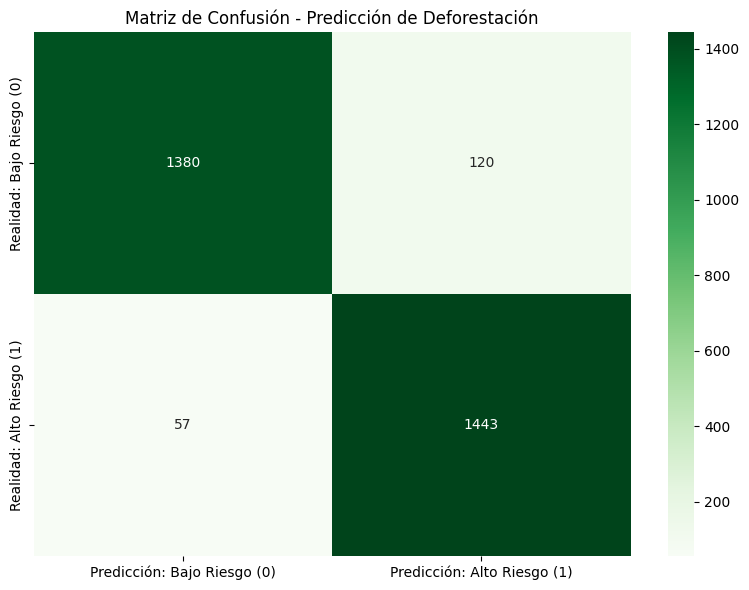

Gráfica guardada en: reportes/matriz_confusion_ae3.png


In [7]:
# 1. Comparación rápida de profundidad del árbol (Justificación de hiperparámetros)
print("=== EXPERIMENTO: COMPARACIÓN DE PROFUNDIDAD DEL ÁRBOL (max_depth) ===")
for profundidad in [4, 8, 12]:
    modelo_prueba = DeforestationClassifier(n_estimators=100, max_depth=profundidad, random_state=42)
    res = modelo_prueba.entrenar_y_evaluar(X_train, X_test, y_train, y_test)
    print(f"Profundidad {profundidad:2d} -> Accuracy: {res['accuracy']} | Recall: {res['recall']} | F1-Score: {res['f1_score']}")

# 2. Entrenamos nuestro modelo definitivo con max_depth=8 (equilibrio entre aprendizaje y simplicidad)
metricas = clasificador.entrenar_y_evaluar(X_train, X_test, y_train, y_test)

print("\n=== MÉTRICAS DEL MODELO DEFINITIVO (max_depth=8) ===")
for clave, valor in metricas.items():
    if clave != "matriz_confusion":
        print(f"- {clave}: {valor}")

# 3. Dibujamos y guardamos la Matriz de Confusión
Path("reportes").mkdir(exist_ok=True)
ruta_grafica = "reportes/matriz_confusion_ae3.png"

plt.figure(figsize=(8, 6))
sns.heatmap(
    metricas["matriz_confusion"],
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Predicción: Bajo Riesgo (0)", "Predicción: Alto Riesgo (1)"],
    yticklabels=["Realidad: Bajo Riesgo (0)", "Realidad: Alto Riesgo (1)"]
)
plt.title("Matriz de Confusión - Predicción de Deforestación")
plt.tight_layout()
plt.savefig(ruta_grafica, dpi=150)
plt.show()
print(f"Gráfica guardada en: {ruta_grafica}")

In [ ]:
ruta_reporte = "reportes/resumen_ae3.txt"
fecha_actual = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

contenido_txt = f"""======================================================================
RESUMEN AUTOMÁTICO DE EJECUCIÓN - ACTIVIDAD EVALUATIVA 3
======================================================================
Fecha y hora de ejecución : {fecha_actual}
Dataset Hugging Face      : electricsheepafrica/africa-synth-climate-deforestation-land-use-change-all
Split utilizado           : train

1. PREGUNTA DE NEGOCIO
----------------------------------------------------------------------
¿Cuáles parcelas de bosque tienen un alto riesgo de sufrir deforestación
severa según su clima y el uso del suelo, para que los guardabosques
prioricen patrullajes y ayudas de conservación antes de la tala?

2. PREPROCESAMIENTO APLICADO
----------------------------------------------------------------------
- Dimensiones iniciales : {df_original.shape[0]} filas x {df_original.shape[1]} columnas
- Limpieza              : Eliminación de duplicados e imputación de nulos (mediana/moda)
- Variable objetivo     : {TARGET_COL} (binaria: 0 = Bajo riesgo, 1 = Alto riesgo)
- Codificación          : One-Hot Encoding (pd.get_dummies) para variables categóricas
- Escalado              : No aplicado (Random Forest es invariante a la escala)
- Partición             : 80% Entrenamiento ({X_train.shape[0]} filas) / 20% Prueba ({X_test.shape[0]} filas)

3. MODELO Y CONFIGURACIÓN
----------------------------------------------------------------------
- Tipo de aprendizaje   : Supervisado (Clasificación Binaria)
- Algoritmo             : Random Forest Classifier
- Hiperparámetros       : {clasificador.params}
- Cantidad de variables : {len(clasificador.features)} variables predictoras

4. MÉTRICAS DE EVALUACIÓN (CONJUNTO DE PRUEBA)
----------------------------------------------------------------------
- Exactitud (Accuracy)  : {metricas['accuracy']}
- Precisión (Precision) : {metricas['precision']}
- Sensibilidad (Recall) : {metricas['recall']}
- F1-Score              : {metricas['f1_score']}
- Matriz de Confusión   : {metricas['matriz_confusion']}
======================================================================
"""

with open(ruta_reporte, "w", encoding="utf-8") as archivo:
    archivo.write(contenido_txt)

print(f"¡Archivo creado con éxito en: {ruta_reporte}!\n")
print(contenido_txt)

¡Archivo creado con éxito en: reportes/resumen_ae3.txt!

RESUMEN AUTOMÁTICO DE EJECUCIÓN - ACTIVIDAD EVALUATIVA 3
Fecha y hora de ejecución : 2026-11-19 13:01:13
Dataset Hugging Face      : electricsheepafrica/africa-synth-climate-deforestation-land-use-change-all
Split utilizado           : train

1. PREGUNTA DE NEGOCIO
----------------------------------------------------------------------
¿Cuáles parcelas de bosque tienen un alto riesgo de sufrir deforestación
severa según su clima y el uso del suelo, para que los guardabosques
prioricen patrullajes y ayudas de conservación antes de la tala?

2. PREPROCESAMIENTO APLICADO
----------------------------------------------------------------------
- Dimensiones iniciales : 15000 filas x 18 columnas
- Limpieza              : Eliminación de duplicados e imputación de nulos (mediana/moda)
- Variable objetivo     : riesgo_alto_deforestacion (binaria: 0 = Bajo riesgo, 1 = Alto riesgo)
- Codificación          : One-Hot Encoding (pd.get_dummies) p